In [24]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

pd.set_option("display.max_columns", None)

In [25]:
SCRIPT_DIR  = Path("/lab/solexa_weissman/tmasuyama/Moonlighting_Project/BE_sensor_analysis")
OUT_DIR = SCRIPT_DIR / "data_for_cheeseman"


final_start_guide_summary = pd.read_csv(OUT_DIR / "start_guide_summary.csv", sep=",",)
final_start_site_summary = pd.read_csv(OUT_DIR / "start_codon_summary.csv", sep=",",)
final_stop_guide_summary = pd.read_csv(OUT_DIR / "stop_guide_summary.csv", sep=",",)
final_stop_site_summary = pd.read_csv(OUT_DIR / "stop_codon_summary.csv", sep=",",)

In [27]:
final_stop_site_summary.columns

Index(['Hugo_Symbol', 'Chromosome', 'strand', 'stop_site_target_id',
       'ClinVar_ID', 'Clinical_Significance', 'reference_codon',
       'target_codon_range', 'target_codon_spans_multiple_exons', 'num_guides',
       'lfc', 'neg_rank', 'neg_lfc', 'neg_rra_score', 'neg_pval', 'neg_fdr',
       'pos_rank', 'pos_lfc', 'pos_rra_score', 'pos_pval', 'pos_fdr',
       'pass_lfc_1_cutoff', 'pass_fdr_0.1_cutoff'],
      dtype='object')

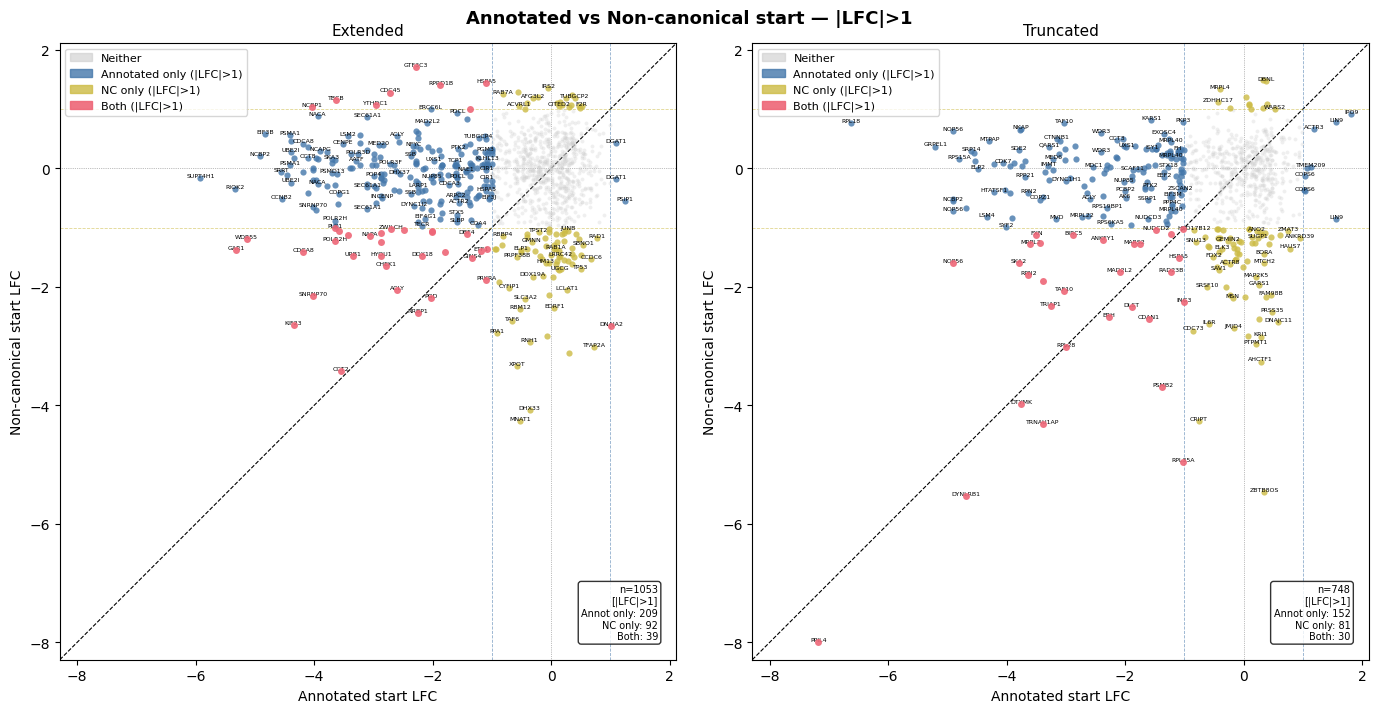

In [ ]:
# # Annotated vs Non-canonical Start Scatter Plots
# One point per row in `final_start_site_summary`.
# x = annotated start LFC, y = non-canonical start LFC.
# Significance: configurable FDR and/or LFC thresholds.

# ============================================================
# CONFIGURATION
# ============================================================

FDR_THRESH = None    # set to None to ignore FDR
LFC_THRESH = 1   # set to e.g. 1.0 to require |lfc| > threshold

SIG_COLORS = {
    "neither"    : "#CCCCCC",
    "annot_only" : "#4477AA",
    "nc_only"    : "#CCBB44",
    "both"       : "#EE6677",
}
SIG_SIZES  = {"neither": 8,  "annot_only": 20, "nc_only": 20, "both": 25}
SIG_ALPHA  = {"neither": 0.3, "annot_only": 0.8, "nc_only": 0.8, "both": 0.9}
SIG_ZORDER = {"neither": 1,   "annot_only": 3,   "nc_only": 3,   "both": 4}

# ============================================================
# SIGNIFICANCE HELPERS
# ============================================================

def _sig_label(fdr_thresh, lfc_thresh):
    parts = []
    if fdr_thresh is not None:
        parts.append(f"FDR<{fdr_thresh}")
    if lfc_thresh is not None:
        parts.append(f"|LFC|>{lfc_thresh}")
    return " & ".join(parts) if parts else "all"

def is_significant(neg_fdr, pos_fdr, lfc,
                   fdr_thresh=FDR_THRESH, lfc_thresh=LFC_THRESH):
    """
    Returns a boolean Series. A point is significant if it passes
    ALL supplied thresholds (thresholds set to None are ignored).
    """
    mask = pd.Series(True, index=neg_fdr.index)
    if fdr_thresh is not None:
        mask &= (neg_fdr < fdr_thresh) | (pos_fdr < fdr_thresh)
    if lfc_thresh is not None:
        mask &= lfc.abs() > lfc_thresh
    return mask

def assign_sig_cat(df, fdr_thresh=FDR_THRESH, lfc_thresh=LFC_THRESH):
    df = df.copy()
    annot_sig = is_significant(df["annot_neg_fdr"], df["annot_pos_fdr"],
                               df["annot_lfc"], fdr_thresh, lfc_thresh)
    nc_sig    = is_significant(df["nc_neg_fdr"],    df["nc_pos_fdr"],
                               df["nc_lfc"],    fdr_thresh, lfc_thresh)
    df["sig_cat"] = "neither"
    df.loc[annot_sig & ~nc_sig, "sig_cat"] = "annot_only"
    df.loc[~annot_sig & nc_sig, "sig_cat"] = "nc_only"
    df.loc[annot_sig  & nc_sig, "sig_cat"] = "both"
    return df

def legend_handles(fdr_thresh=FDR_THRESH, lfc_thresh=LFC_THRESH):
    label = _sig_label(fdr_thresh, lfc_thresh)
    return [
        mpatches.Patch(color=SIG_COLORS["neither"],    alpha=0.6, label="Neither"),
        mpatches.Patch(color=SIG_COLORS["annot_only"], alpha=0.8, label=f"Annotated only ({label})"),
        mpatches.Patch(color=SIG_COLORS["nc_only"],    alpha=0.8, label=f"NC only ({label})"),
        mpatches.Patch(color=SIG_COLORS["both"],       alpha=0.9, label=f"Both ({label})"),
    ]

# ============================================================
# PLOT FUNCTION
# ============================================================

def plot_scatter(df, ax, title="", lim=None,
                 fdr_thresh=FDR_THRESH, lfc_thresh=LFC_THRESH):
    if lim is None:
        pad = 0.3
        lim = [min(df["annot_lfc"].min(), df["nc_lfc"].min()) - pad,
               max(df["annot_lfc"].max(), df["nc_lfc"].max()) + pad]

    for cat in ["neither", "annot_only", "nc_only", "both"]:
        mask = df["sig_cat"] == cat
        if not mask.any():
            continue
        ax.scatter(
            df.loc[mask, "annot_lfc"], df.loc[mask, "nc_lfc"],
            c=SIG_COLORS[cat], s=SIG_SIZES[cat],
            alpha=SIG_ALPHA[cat], zorder=SIG_ZORDER[cat],
            linewidths=0, rasterized=True,
        )

    ax.plot(lim, lim, color="black", lw=0.8, ls="--", zorder=0)
    ax.axhline(0, color="gray", lw=0.5, ls=":", zorder=0)
    ax.axvline(0, color="gray", lw=0.5, ls=":", zorder=0)

    # Draw LFC threshold lines if set
    if lfc_thresh is not None:
        for v in (-lfc_thresh, lfc_thresh):
            ax.axhline(v, color=SIG_COLORS["nc_only"],    lw=0.6, ls="--", zorder=0, alpha=0.6)
            ax.axvline(v, color=SIG_COLORS["annot_only"], lw=0.6, ls="--", zorder=0, alpha=0.6)

    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_aspect("equal")
    ax.set_xlabel("Annotated start LFC", fontsize=10)
    ax.set_ylabel("Non-canonical start LFC", fontsize=10)
    if title:
        ax.set_title(title, fontsize=11)

    # Label extreme points (beyond lfc_thresh or 1.0 if no lfc_thresh), drop overlaps
    label_cutoff = lfc_thresh if lfc_thresh is not None else 1.0
    label_df = (
        df[(df["annot_lfc"].abs() > label_cutoff) | (df["nc_lfc"].abs() > label_cutoff)]
        .assign(_p=lambda d: d["annot_lfc"].abs() + d["nc_lfc"].abs())
        .sort_values("_p", ascending=False)
    )
    if not label_df.empty:
        ax.figure.canvas.draw()
        renderer = ax.figure.canvas.get_renderer()
        placed = []
        for _, row in label_df.iterrows():
            t = ax.text(row["annot_lfc"], row["nc_lfc"], row["Hugo_Symbol"],
                        fontsize=4.5, ha="center", va="bottom", color="black")
            bb = t.get_window_extent(renderer=renderer)
            if any(bb.overlaps(b) for b in placed):
                t.remove()
            else:
                placed.append(bb)

    cats = df["sig_cat"].value_counts()
    ax.text(0.97, 0.03,
            f"n={len(df)}\n[{_sig_label(fdr_thresh, lfc_thresh)}]\n"
            f"Annot only: {cats.get('annot_only', 0)}\n"
            f"NC only: {cats.get('nc_only', 0)}\n"
            f"Both: {cats.get('both', 0)}",
            transform=ax.transAxes, fontsize=7, va="bottom", ha="right",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))

# ============================================================
# PREPARE DATA
# ============================================================

df = assign_sig_cat(final_start_site_summary,
                    fdr_thresh=FDR_THRESH, lfc_thresh=LFC_THRESH)

nc_types   = df["nc_start_site_type"].dropna().unique().tolist()
all_lfc    = pd.concat([df["annot_lfc"], df["nc_lfc"]])
global_lim = [all_lfc.min() - 0.3, all_lfc.max() + 0.3]

# ============================================================
# PLOT — one panel per nc_start_site_type
# ============================================================

n_types = len(nc_types)
fig, axes = plt.subplots(1, max(n_types, 1),
                         figsize=(7 * max(n_types, 1), 7), squeeze=False)

for ax, nc_type in zip(axes[0], nc_types if n_types else [None]):
    subset = df[df["nc_start_site_type"] == nc_type] if nc_type else df
    plot_scatter(subset, ax, title=nc_type or "All", lim=global_lim,
                 fdr_thresh=FDR_THRESH, lfc_thresh=LFC_THRESH)
    ax.legend(handles=legend_handles(FDR_THRESH, LFC_THRESH),
              fontsize=8, loc="upper left", framealpha=0.8)

fig.suptitle(
    f"Annotated vs Non-canonical start — {_sig_label(FDR_THRESH, LFC_THRESH)}",
    fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

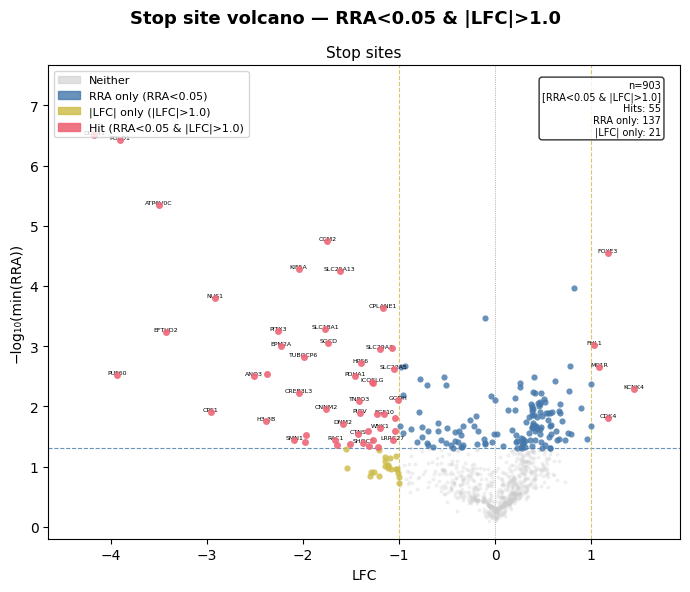

In [33]:
# # Stop Site Volcano Plots
# One point per row in `final_stop_site_summary`.
# x = LFC, y = -log10(RRA score)  [neg and pos sides plotted separately or together]
# Significance: configurable RRA and/or LFC thresholds.

# ============================================================
# CONFIGURATION
# ============================================================

RRA_THRESH = 0.05   # threshold on RRA score (neg or pos); None to disable
LFC_THRESH = 1.0    # threshold on |lfc|; None to disable

# Which RRA column to use for the volcano y-axis: "neg", "pos", or "min"
# "min" uses whichever of neg_rra_score / pos_rra_score is smaller (most significant)
RRA_SIDE = "min"

SIG_COLORS = {
    "neither"  : "#CCCCCC",
    "rra_only" : "#4477AA",
    "lfc_only" : "#CCBB44",
    "both"     : "#EE6677",
}
SIG_SIZES  = {"neither": 8,  "rra_only": 20, "lfc_only": 20, "both": 25}
SIG_ALPHA  = {"neither": 0.3, "rra_only": 0.8, "lfc_only": 0.8, "both": 0.9}
SIG_ZORDER = {"neither": 1,   "rra_only": 3,   "lfc_only": 3,   "both": 4}

# ============================================================
# HELPERS
# ============================================================

def _sig_label(rra_thresh, lfc_thresh):
    parts = []
    if rra_thresh is not None:
        parts.append(f"RRA<{rra_thresh}")
    if lfc_thresh is not None:
        parts.append(f"|LFC|>{lfc_thresh}")
    return " & ".join(parts) if parts else "all"

def _effective_rra(df, side=RRA_SIDE):
    if side == "neg":
        return df["neg_rra_score"]
    elif side == "pos":
        return df["pos_rra_score"]
    else:  # "min"
        return df[["neg_rra_score", "pos_rra_score"]].min(axis=1)

def assign_sig_cat(df, rra_thresh=RRA_THRESH, lfc_thresh=LFC_THRESH,
                   rra_side=RRA_SIDE):
    df = df.copy()
    rra = _effective_rra(df, rra_side)
    rra_sig = (rra < rra_thresh)                 if rra_thresh is not None else pd.Series(False, index=df.index)
    lfc_sig = (df["lfc"].abs() > lfc_thresh)     if lfc_thresh is not None else pd.Series(False, index=df.index)
    df["sig_cat"] = "neither"
    df.loc[rra_sig & ~lfc_sig, "sig_cat"] = "rra_only"
    df.loc[~rra_sig & lfc_sig, "sig_cat"] = "lfc_only"
    df.loc[rra_sig  & lfc_sig, "sig_cat"] = "both"
    df["_rra_plot"] = rra
    return df

def legend_handles(rra_thresh=RRA_THRESH, lfc_thresh=LFC_THRESH):
    label = _sig_label(rra_thresh, lfc_thresh)
    entries = [mpatches.Patch(color=SIG_COLORS["neither"], alpha=0.6, label="Neither")]
    if rra_thresh is not None:
        entries.append(mpatches.Patch(color=SIG_COLORS["rra_only"], alpha=0.8,
                                      label=f"RRA only (RRA<{rra_thresh})"))
    if lfc_thresh is not None:
        entries.append(mpatches.Patch(color=SIG_COLORS["lfc_only"], alpha=0.8,
                                      label=f"|LFC| only (|LFC|>{lfc_thresh})"))
    entries.append(mpatches.Patch(color=SIG_COLORS["both"], alpha=0.9,
                                  label=f"Hit ({label})"))
    return entries

# ============================================================
# PLOT FUNCTION
# ============================================================

def plot_volcano(df, ax, title="",
                 rra_thresh=RRA_THRESH, lfc_thresh=LFC_THRESH,
                 xlim=None, ylim=None):
    """
    Volcano: x = lfc, y = -log10(RRA score).
    df must already have sig_cat and _rra_plot columns (from assign_sig_cat).
    """
    y = -np.log10(df["_rra_plot"].clip(lower=1e-300))

    for cat in ["neither", "rra_only", "lfc_only", "both"]:
        mask = df["sig_cat"] == cat
        if not mask.any():
            continue
        ax.scatter(
            df.loc[mask, "lfc"], y[mask],
            c=SIG_COLORS[cat], s=SIG_SIZES[cat],
            alpha=SIG_ALPHA[cat], zorder=SIG_ZORDER[cat],
            linewidths=0, rasterized=True,
        )

    # Threshold lines
    if rra_thresh is not None:
        yline = -np.log10(rra_thresh)
        ax.axhline(yline, color=SIG_COLORS["rra_only"], lw=0.8, ls="--",
                   zorder=0, alpha=0.8)
    if lfc_thresh is not None:
        for v in (-lfc_thresh, lfc_thresh):
            ax.axvline(v, color=SIG_COLORS["lfc_only"], lw=0.8, ls="--",
                       zorder=0, alpha=0.8)
    ax.axvline(0, color="gray", lw=0.5, ls=":", zorder=0)

    # Axis limits
    pad_x = (df["lfc"].max() - df["lfc"].min()) * 0.05 + 0.2
    ax.set_xlim(xlim or [df["lfc"].min() - pad_x, df["lfc"].max() + pad_x])
    ax.set_ylim(ylim or [-0.2, y.max() * 1.1 + 0.5])
    ax.set_xlabel("LFC", fontsize=10)
    rra_col_label = {"neg": "neg RRA", "pos": "pos RRA", "min": "min(RRA)"}[RRA_SIDE]
    ax.set_ylabel(f"−log₁₀({rra_col_label})", fontsize=10)
    if title:
        ax.set_title(title, fontsize=11)

    # Label hits (both thresholds), fall back to |lfc| > cutoff if none qualify
    hit_mask = df["sig_cat"] == "both"
    if not hit_mask.any():
        label_cutoff_x = lfc_thresh if lfc_thresh is not None else 1.0
        hit_mask = df["lfc"].abs() > label_cutoff_x

    label_df = (
        df[hit_mask]
        .assign(_priority=lambda d: d["lfc"].abs() + (-np.log10(d["_rra_plot"].clip(1e-300))))
        .sort_values("_priority", ascending=False)
    )
    if not label_df.empty:
        ax.figure.canvas.draw()
        renderer = ax.figure.canvas.get_renderer()
        placed = []
        for _, row in label_df.iterrows():
            yval = -np.log10(max(row["_rra_plot"], 1e-300))
            t = ax.text(row["lfc"], yval, row["Hugo_Symbol"],
                        fontsize=4.5, ha="center", va="bottom", color="black")
            bb = t.get_window_extent(renderer=renderer)
            if any(bb.overlaps(b) for b in placed):
                t.remove()
            else:
                placed.append(bb)

    cats = df["sig_cat"].value_counts()
    ax.text(0.97, 0.97,
            f"n={len(df)}\n[{_sig_label(rra_thresh, lfc_thresh)}]\n"
            f"Hits: {cats.get('both', 0)}\n"
            f"RRA only: {cats.get('rra_only', 0)}\n"
            f"|LFC| only: {cats.get('lfc_only', 0)}",
            transform=ax.transAxes, fontsize=7, va="top", ha="right",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))

# ============================================================
# PREPARE DATA
# ============================================================

df = assign_sig_cat(final_stop_site_summary,
                    rra_thresh=RRA_THRESH, lfc_thresh=LFC_THRESH,
                    rra_side=RRA_SIDE)

# ============================================================
# PLOT — single volcano (all stop sites)
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))
plot_volcano(df, ax, title="Stop sites",
             rra_thresh=RRA_THRESH, lfc_thresh=LFC_THRESH)
ax.legend(handles=legend_handles(RRA_THRESH, LFC_THRESH),
          fontsize=8, loc="upper left", framealpha=0.8)
fig.suptitle(f"Stop site volcano — {_sig_label(RRA_THRESH, LFC_THRESH)}",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
